In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean',
    'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se',
    'smoothness_se', 'compactness_se', 'concavity_se',
    'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
    'smoothness_worst', 'compactness_worst', 'concavity_worst',
    'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

In [4]:
df = pd.read_csv("data.csv", header=None, names=columns)

In [5]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df.shape

(569, 32)

In [7]:
df = df.drop(columns=['id'])
df = df.drop_duplicates()

In [8]:
df['diagnosis'] = df['diagnosis'].astype(str).str.strip().map({'B': 0,'M': 1})

In [9]:
df = df.dropna(subset=['diagnosis'])

In [10]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis'].astype(int)

X = X.fillna(X.median())

In [11]:
print("Missing values:", X.isnull().sum())

Missing values: radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


In [12]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (569, 30)
Target: (569,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
svm = SVC()
svm.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [16]:
svm_pred = svm.predict(X_test_scaled)

In [17]:
print("SVM Before Tuning")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1 Score:", f1_score(y_test, svm_pred))

SVM Before Tuning
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


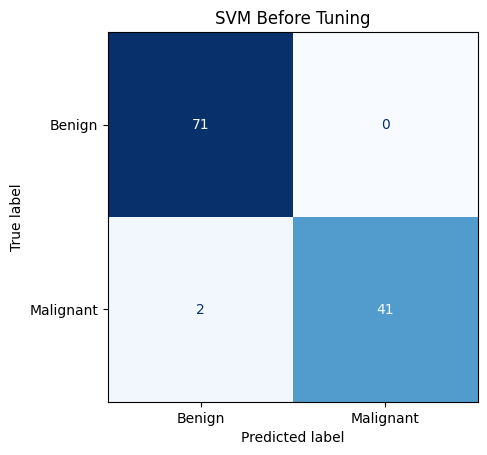

In [18]:
cm = confusion_matrix(y_test, svm_pred)

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Benign', 'Malignant']).plot(cmap='Blues', colorbar=False)

plt.title("SVM Before Tuning")
plt.show()

In [19]:
svm_cv = cross_val_score(SVC(),X_train_scaled,y_train,cv=5,scoring='f1')

print("SVM Cross-Validation Scores:", svm_cv)
print("Mean CV F1 Score:", svm_cv.mean())

SVM Cross-Validation Scores: [0.97058824 0.95522388 0.98507463 0.98507463 0.9375    ]
Mean CV F1 Score: 0.9666922739244951


In [20]:
svm_params = {'C': [0.1, 1, 10],'kernel': ['linear', 'rbf'],'gamma': ['scale', 0.01, 0.1]}

svm_grid = GridSearchCV(SVC(),svm_params,cv=5,scoring='f1',n_jobs=-1)

In [21]:
svm_grid.fit(X_train_scaled, y_train)

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 0.01, ...], 'kernel': ['linear', 'rbf']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


In [22]:
print("Best SVM Parameters:", svm_grid.best_params_)
print("Best CV F1 Score:", svm_grid.best_score_)

Best SVM Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV F1 Score: 0.9666922739244951


In [23]:
best_svm = svm_grid.best_estimator_

In [24]:
svm_tuned_pred = best_svm.predict(X_test_scaled)

In [25]:
print("SVM After Tuning")
print("Accuracy:", accuracy_score(y_test, svm_tuned_pred))
print("Precision:", precision_score(y_test, svm_tuned_pred))
print("Recall:", recall_score(y_test, svm_tuned_pred))
print("F1 Score:", f1_score(y_test, svm_tuned_pred))

SVM After Tuning
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


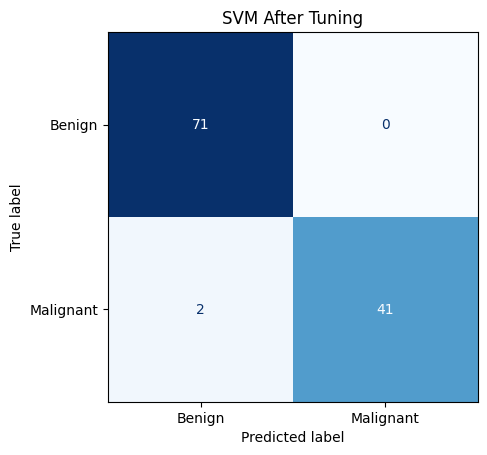

In [26]:
cm = confusion_matrix(y_test, svm_tuned_pred)

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Benign', 'Malignant']).plot(cmap='Blues', colorbar=False)

plt.title("SVM After Tuning")
plt.show()

In [27]:
rf = RandomForestClassifier(random_state=42)

In [28]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
rf_pred = rf.predict(X_test)

In [30]:
print("Random Forest Before Tuning")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

Random Forest Before Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


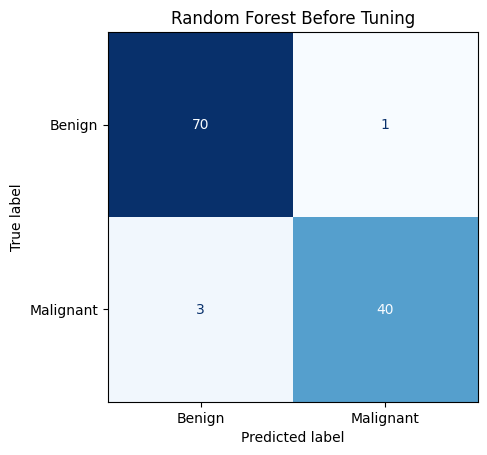

In [31]:
cm = confusion_matrix(y_test, rf_pred)

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Benign', 'Malignant']).plot(cmap='Blues', colorbar=False)

plt.title("Random Forest Before Tuning")
plt.show()

In [32]:
rf_cv = cross_val_score(RandomForestClassifier(random_state=42),X_train,y_train,cv=5,scoring='f1')

print("Random Forest CV Scores:", rf_cv)
print("Mean CV F1 Score:", rf_cv.mean())

Random Forest CV Scores: [0.95238095 0.92307692 0.97142857 0.94117647 0.90909091]
Mean CV F1 Score: 0.9394307653131182


In [33]:
rf_params = {'n_estimators': [100, 200],'max_depth': [None, 5, 10],'min_samples_split': [2, 5]}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),rf_params,cv=5, scoring='f1', n_jobs=-1)

In [34]:
rf_grid.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 5, ...], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [35]:
print("Best Random Forest Parameters:", rf_grid.best_params_)
print("Best CV F1 Score:", rf_grid.best_score_)

Best Random Forest Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 Score: 0.9487651808975338


In [36]:
best_rf = rf_grid.best_estimator_

In [37]:
rf_tuned_pred = best_rf.predict(X_test)

In [38]:
print("Random Forest After Tuning")
print("Accuracy:", accuracy_score(y_test, rf_tuned_pred))
print("Precision:", precision_score(y_test, rf_tuned_pred))
print("Recall:", recall_score(y_test, rf_tuned_pred))
print("F1 Score:", f1_score(y_test, rf_tuned_pred))

Random Forest After Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


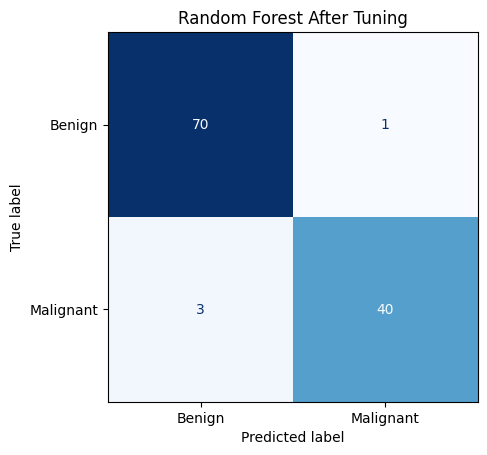

In [39]:
cm = confusion_matrix(y_test, rf_tuned_pred)

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Benign', 'Malignant']).plot(cmap='Blues', colorbar=False)

plt.title("Random Forest After Tuning")
plt.show()

In [40]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


In [41]:
ada_pred = ada.predict(X_test)

In [42]:
print("AdaBoost Before Tuning")
print("Accuracy:", accuracy_score(y_test, ada_pred))
print("Precision:", precision_score(y_test, ada_pred))
print("Recall:", recall_score(y_test, ada_pred))
print("F1 Score:", f1_score(y_test, ada_pred))

AdaBoost Before Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


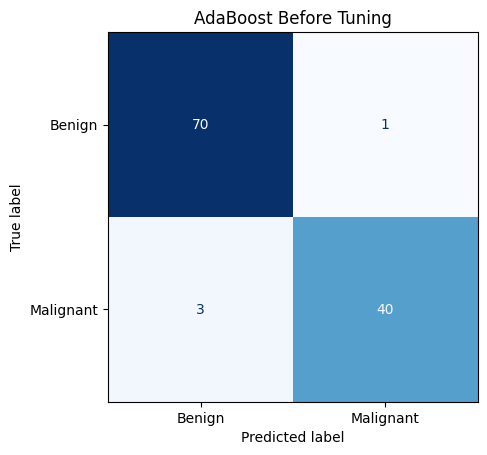

In [43]:
cm = confusion_matrix(y_test, ada_pred)

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Benign', 'Malignant']).plot(cmap='Blues', colorbar=False)

plt.title("AdaBoost Before Tuning")
plt.show()

In [44]:
ada_cv = cross_val_score(AdaBoostClassifier(random_state=42),X_train,y_train,cv=5,scoring='f1')

In [45]:
print("AdaBoost CV Scores:", ada_cv)
print("Mean CV F1 Score:", ada_cv.mean())

AdaBoost CV Scores: [0.97058824 0.96969697 1.         0.96969697 0.95384615]
Mean CV F1 Score: 0.9727656657068422


In [46]:
ada_params = {'n_estimators': [50, 100, 200],'learning_rate': [0.1, 0.5, 1.0],'estimator': [DecisionTreeClassifier(max_depth=1, random_state=42),
        DecisionTreeClassifier(max_depth=2, random_state=42)]}

ada_grid = GridSearchCV( AdaBoostClassifier(random_state=42),ada_params,cv=5,scoring='f1',n_jobs=-1)

In [47]:
ada_grid.fit(X_train, y_train)

,estimator,AdaBoostClass...ndom_state=42)
,param_grid,"{'estimator': [DecisionTreeC...ndom_state=42), DecisionTreeC...ndom_state=42)], 'learning_rate': [0.1, 0.5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [48]:
print("Best AdaBoost Parameters:", ada_grid.best_params_)
print("Best CV F1 Score:", ada_grid.best_score_)

Best AdaBoost Parameters: {'estimator': DecisionTreeClassifier(max_depth=1, random_state=42), 'learning_rate': 1.0, 'n_estimators': 50}
Best CV F1 Score: 0.9727656657068422


In [49]:
best_ada = ada_grid.best_estimator_

In [50]:
ada_tuned_pred = best_ada.predict(X_test)

In [51]:
print("AdaBoost After Tuning")
print("Accuracy:", accuracy_score(y_test, ada_tuned_pred))
print("Precision:", precision_score(y_test, ada_tuned_pred))
print("Recall:", recall_score(y_test, ada_tuned_pred))
print("F1 Score:", f1_score(y_test, ada_tuned_pred))

AdaBoost After Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


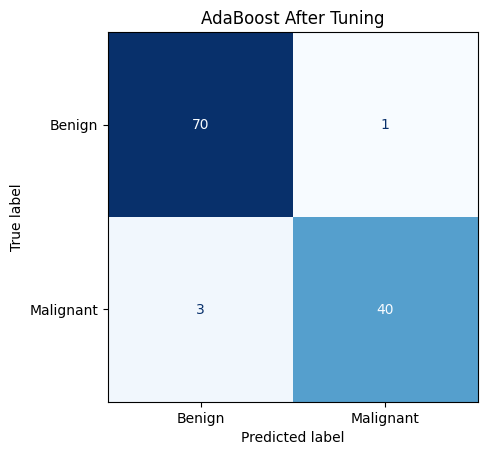

In [52]:
cm = confusion_matrix(y_test, ada_tuned_pred)

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Benign', 'Malignant']).plot(cmap='Blues', colorbar=False)

plt.title("AdaBoost After Tuning")
plt.show()

In [53]:
comparison = pd.DataFrame({'Model': ['SVM', 'SVM Tuned','Random Forest', 'Random Forest Tuned', 'AdaBoost', 'AdaBoost Tuned'],

    'Accuracy': [
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, svm_tuned_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, rf_tuned_pred),
        accuracy_score(y_test, ada_pred),
        accuracy_score(y_test, ada_tuned_pred)
    ],

    'Precision': [
        precision_score(y_test, svm_pred),
        precision_score(y_test, svm_tuned_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, rf_tuned_pred),
        precision_score(y_test, ada_pred),
        precision_score(y_test, ada_tuned_pred)
    ],

    'Recall': [
        recall_score(y_test, svm_pred),
        recall_score(y_test, svm_tuned_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, rf_tuned_pred),
        recall_score(y_test, ada_pred),
        recall_score(y_test, ada_tuned_pred)
    ],

    'F1 Score': [
        f1_score(y_test, svm_pred),
        f1_score(y_test, svm_tuned_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, rf_tuned_pred),
        f1_score(y_test, ada_pred),
        f1_score(y_test, ada_tuned_pred)
    ]
})

print(comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0                  SVM    0.9825     1.0000  0.9535    0.9762
1            SVM Tuned    0.9825     1.0000  0.9535    0.9762
2        Random Forest    0.9649     0.9756  0.9302    0.9524
3  Random Forest Tuned    0.9649     0.9756  0.9302    0.9524
4             AdaBoost    0.9649     0.9756  0.9302    0.9524
5       AdaBoost Tuned    0.9649     0.9756  0.9302    0.9524


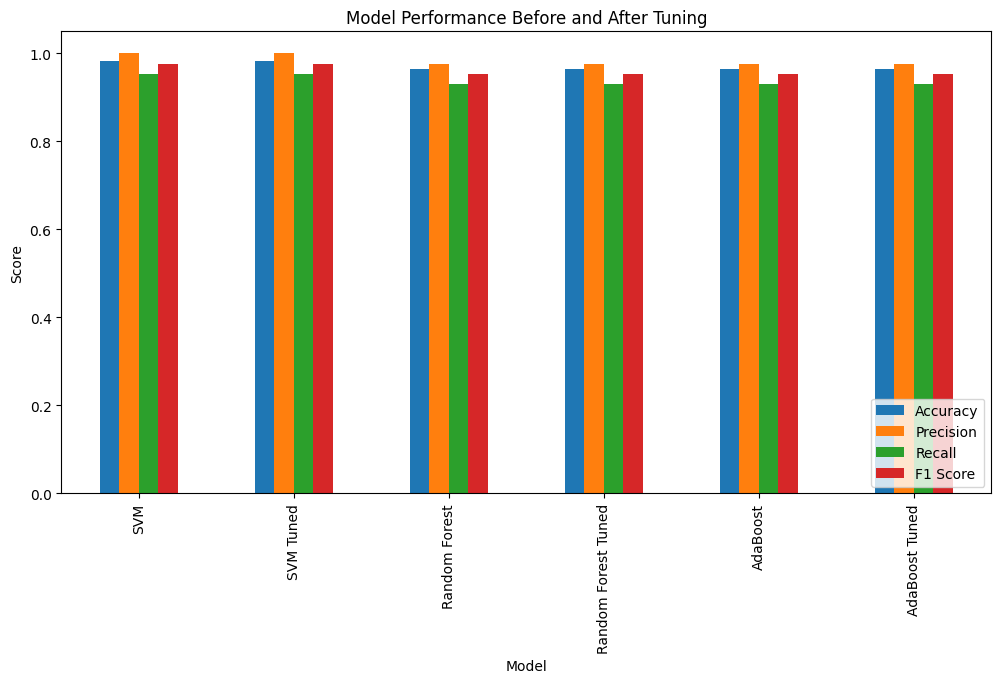

In [54]:
comparison.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(kind='bar', figsize=(12, 6))

plt.title('Model Performance Before and After Tuning')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.show()